# Investigação de Degradação de Desempenho em Servidores
## Estimação Numérica de Temperaturas por Interpolação de Newton

Este notebook tem como objetivo estimar numericamente a temperatura dos processadores de três servidores (`SRV-01`, `SRV-02` e `SRV-03`) em momentos críticos de degradação de desempenho, utilizando o **Método de Interpolação Polinomial de Newton por Diferenças Divididas**.

---

### Contexto do Problema
Uma empresa de tecnologia monitora a temperatura dos processadores de três servidores em seu data center. As medições foram coletadas em intervalos de 1 hora, durante um período de 10 horas (das 14:00 às 23:00 do dia 05/11/2026), e registradas no arquivo `data/temperaturas.csv`.

Durante esse período, foram registrados três episódios de degradação de desempenho no arquivo `data/incidentes.log`:
1. **15:30:00** ($t = 15.5\text{ h}$)
2. **18:30:00** ($t = 18.5\text{ h}$)
3. **21:30:00** ($t = 21.5\text{ h}$)

Como os incidentes ocorreram em horários intermediários sem medição direta, aplicamos métodos numéricos de interpolação para:
* Estimar a temperatura de cada servidor nos horários em que ocorreram os incidentes;
* Verificar se algum dos servidores apresentou temperatura próxima ou superior ao limite operacional de **80 °C**;
* Analisar graficamente o comportamento térmico ao longo do período de monitoramento.

In [1]:
import os
import sys
import csv
import re
from datetime import datetime
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuração estética dos gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

## Carregamento dos Dados

Os dados brutos de temperatura e registros de incidentes são lidos a partir de `data/temperaturas.csv` e `data/incidentes.log`.

In [2]:
caminho_dados = os.path.join("..", "data")
if not os.path.exists(caminho_dados):
    caminho_dados = "data"

arquivo_temp = os.path.join(caminho_dados, "temperaturas.csv")
arquivo_inc = os.path.join(caminho_dados, "incidentes.log")

# Leitura e parsing dos incidentes registrados
incidentes = []
regex_log = re.compile(r"^(\d{4}-\d{2}-\d{2}\s+(\d{2}):(\d{2}):(\d{2}))")
with open(arquivo_inc, "r", encoding="utf-8") as f:
    for linha in f:
        m = regex_log.match(linha.strip())
        if m:
            data_hora_str = m.group(1)
            h, mi, s = int(m.group(2)), int(m.group(3)), int(m.group(4))
            t_hora = h + mi / 60.0 + s / 3600.0
            incidentes.append({
                "data_hora": data_hora_str,
                "hora": t_hora,
                "hora_str": f"{h:02d}:{mi:02d}"
            })

# Leitura das medições horárias de temperatura
df_temp = pd.read_csv(arquivo_temp)
df_temp["data_hora"] = pd.to_datetime(df_temp["data_hora"])
df_temp["hora"] = df_temp["data_hora"].dt.hour + df_temp["data_hora"].dt.minute / 60.0

# Formatação tabular das medições
tabela_medicoes = df_temp.pivot(index="hora", columns="servidor_id", values="temperatura_c")
tabela_medicoes.reset_index(inplace=True)
tabela_medicoes.insert(0, "Horário", [f"{int(h):02d}:00" for h in tabela_medicoes["hora"]])

print("Medições de Temperatura Coletadas (14:00 às 23:00):")
display(tabela_medicoes[["Horário", "SRV-01", "SRV-02", "SRV-03"]])

Medições de Temperatura Coletadas (14:00 às 23:00):


C:\Users\albuq\AppData\Local\Temp\ipykernel_10620\326207142.py:31: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  tabela_medicoes.reset_index(inplace=True)


servidor_id,Horário,SRV-01,SRV-02,SRV-03
0,14:00,49.75,54.77,58.99
1,15:00,48.79,56.27,59.40
2,16:00,49.97,58.12,63.77
3,17:00,51.28,58.54,71.24
4,18:00,48.65,60.16,79.48
5,19:00,48.65,62.66,79.81
6,20:00,51.37,66.74,71.37
7,21:00,50.15,74.48,63.92
8,22:00,48.30,75.37,59.21
9,23:00,49.81,71.04,58.11


## Método de Interpolação de Newton por Diferenças Divididas

O Método de Newton expressa o polinômio interpolador $P_n(t)$ através da tabela de diferenças divididas:

$$
P_n(t) = f[t_0] + \sum_{k=1}^n f[t_0, t_1, \dots, t_k] \prod_{j=0}^{k-1} (t - t_j)
$$

As diferenças divididas são definidas recursivamente por:

$$
f[t_i] = y_i
$$

$$
f[t_i, t_{i+1}, \dots, t_{i+k}] = \frac{f[t_{i+1}, \dots, t_{i+k}] - f[t_i, \dots, t_{i+k-1}]}{t_{i+k} - t_i}
$$

Para avaliar o polinômio resultante de forma computacionalmente eficiente em $O(n)$, utiliza-se o **algoritmo aninhado de Horner**:

$$
P_n(t) = a_0 + (t - t_0) \Big( a_1 + (t - t_1) \big( a_2 + \dots + (t - t_{n-1}) a_n \big) \Big)
$$

A implementação está estruturada no módulo próprio `src/metodos/newton.py`, fornecendo as funções `calcular_diferencas_divididas(x, y)` e `interpolacao_newton(x, y, valor)`.

In [3]:
from metodos.newton import interpolacao_newton

### Teste de Validação do Método de Newton

Antes de aplicar aos dados reais, validamos o algoritmo com o teste unitário (`tests/test_newton.py`):

In [4]:
x_teste = [0, 1, 2]
y_teste = [58.99, 59.40, 63.77]
valor_teste = 1.5
esperado_teste = 61.09

resultado_teste = interpolacao_newton(x_teste, y_teste, valor_teste)

print("Resultado obtido  :", resultado_teste)
print("Resultado esperado:", esperado_teste)

assert abs(resultado_teste - esperado_teste) < 0.0001

Resultado obtido  : 61.09
Resultado esperado: 61.09


### Aplicação aos Dados dos Servidores

Para cada incidente ($15\text{h}30$, $18\text{h}30$ e $21\text{h}30$), utilizamos os 3 nós de medição vizinhos mais próximos ($t-1, t, t+1$), gerando uma interpolação local de grau 2 (quadrática) que evita oscilações espúrias e reflete o comportamento local da temperatura:

In [5]:
dados = {
    "SRV-01": {
        15.5: ([14, 15, 16], [49.75, 48.79, 49.97]),
        18.5: ([17, 18, 19], [51.28, 48.65, 48.65]),
        21.5: ([20, 21, 22], [51.37, 50.15, 48.30])
    },
    "SRV-02": {
        15.5: ([14, 15, 16], [54.77, 56.27, 58.12]),
        18.5: ([17, 18, 19], [58.54, 60.16, 62.66]),
        21.5: ([20, 21, 22], [66.74, 74.48, 75.37])
    },
    "SRV-03": {
        15.5: ([14, 15, 16], [58.99, 59.40, 63.77]),
        18.5: ([17, 18, 19], [71.24, 79.48, 79.81]),
        21.5: ([20, 21, 22], [71.37, 63.92, 59.21])
    }
}

registros_estimativas = []

for servidor, incidentes_srv in dados.items():
    print(f"\n{servidor}")
    for horario, pontos in incidentes_srv.items():
        x_pts, y_pts = pontos
        temperatura = interpolacao_newton(x_pts, y_pts, horario)
        print(f"Horário: {int(horario)}h30 | Temperatura estimada: {temperatura:.5f} °C")
        
        registros_estimativas.append({
            "Servidor": servidor,
            "Horário": f"{int(horario)}h30",
            "hora": horario,
            "Pontos Utilizados (x)": str(x_pts),
            "Temperatura Estimada (°C)": round(temperatura, 2)
        })


SRV-01
Horário: 15h30 | Temperatura estimada: 49.11250 °C
Horário: 18h30 | Temperatura estimada: 48.32125 °C
Horário: 21h30 | Temperatura estimada: 49.30375 °C

SRV-02
Horário: 15h30 | Temperatura estimada: 57.15125 °C
Horário: 18h30 | Temperatura estimada: 61.30000 °C
Horário: 21h30 | Temperatura estimada: 75.78125 °C

SRV-03
Horário: 15h30 | Temperatura estimada: 61.09000 °C
Horário: 18h30 | Temperatura estimada: 80.63375 °C
Horário: 21h30 | Temperatura estimada: 61.22250 °C


### Resultado — Método de Newton

A tabela a seguir consolida as temperaturas estimadas pelo Método de Newton para cada servidor nos horários dos incidentes:

In [6]:
df_resultados = pd.DataFrame(registros_estimativas)

tabela_resumo = df_resultados.pivot(index="Horário", columns="Servidor", values="Temperatura Estimada (°C)")
display(tabela_resumo)

Servidor,SRV-01,SRV-02,SRV-03
Horário,,,
15h30,49.11,57.15,61.09
18h30,48.32,61.30,80.63
21h30,49.30,75.78,61.22


## Análise do Limite Operacional de 80 °C

Avaliamos as estimativas obtidas por Newton em relação ao limite crítico de **80 °C**:

In [7]:
limite_critico = 80.0
limite_alerta = 75.0

print("Análise em Relação ao Limite Operacional de 80.0 °C:")
print("-" * 65)

for srv in ["SRV-01", "SRV-02", "SRV-03"]:
    sub = df_resultados[df_resultados["Servidor"] == srv]
    print(f"\n* Servidor {srv}:")
    for _, row in sub.iterrows():
        temp = row["Temperatura Estimada (°C)"]
        hora = row["Horário"]
        if temp >= limite_critico:
            status = "SUPERIOR AO LIMITE DE 80 °C (CRÍTICO!)"
        elif temp >= limite_alerta:
            status = "PRÓXIMO AO LIMITE (ALERTA TÉRMICO!)"
        else:
            status = "NORMAL (SEGURO)"
        print(f"  - Incidente das {hora}: {temp:.2f} °C -> {status}")

Análise em Relação ao Limite Operacional de 80.0 °C:
-----------------------------------------------------------------

* Servidor SRV-01:
  - Incidente das 15h30: 49.11 °C -> NORMAL (SEGURO)
  - Incidente das 18h30: 48.32 °C -> NORMAL (SEGURO)
  - Incidente das 21h30: 49.30 °C -> NORMAL (SEGURO)

* Servidor SRV-02:
  - Incidente das 15h30: 57.15 °C -> NORMAL (SEGURO)
  - Incidente das 18h30: 61.30 °C -> NORMAL (SEGURO)
  - Incidente das 21h30: 75.78 °C -> PRÓXIMO AO LIMITE (ALERTA TÉRMICO!)

* Servidor SRV-03:
  - Incidente das 15h30: 61.09 °C -> NORMAL (SEGURO)
  - Incidente das 18h30: 80.63 °C -> SUPERIOR AO LIMITE DE 80 °C (CRÍTICO!)
  - Incidente das 21h30: 61.22 °C -> NORMAL (SEGURO)


## Representação Gráfica

O gráfico a seguir apresenta as curvas de temperatura dos três servidores ao longo do período de monitoramento e os pontos estimados pelo Método de Newton nos horários dos incidentes.

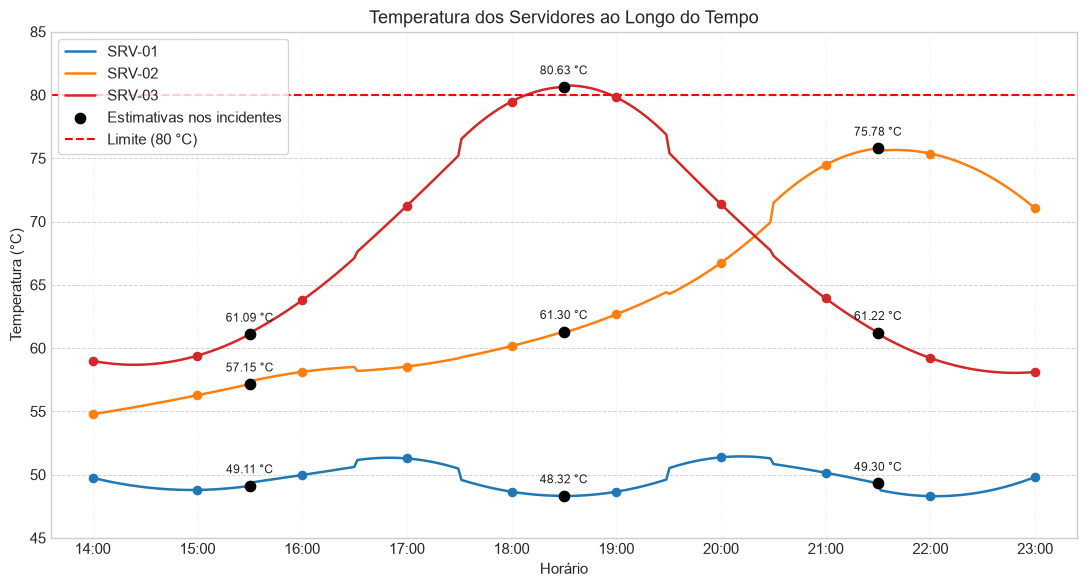

In [ ]:
plt.figure(figsize=(11, 6))

cores = {"SRV-01": "#1f77b4", "SRV-02": "#ff7f0e", "SRV-03": "#d62728"}
t_curva = np.linspace(14, 23, 300)

for srv in ["SRV-01", "SRV-02", "SRV-03"]:
    sub = df_temp[df_temp["servidor_id"] == srv].sort_values("hora")
    x_dados = sub["hora"].tolist()
    y_dados = sub["temperatura_c"].tolist()
    
    y_curva = []
    for t_val in t_curva:
        idx = np.argsort(np.abs(np.array(x_dados) - t_val))[:3]
        x_loc = [x_dados[i] for i in sorted(idx)]
        y_loc = [y_dados[i] for i in sorted(idx)]
        y_curva.append(interpolacao_newton(x_loc, y_loc, t_val))
        
    plt.plot(t_curva, y_curva, color=cores[srv], label=srv, linewidth=1.8)
    plt.scatter(x_dados, y_dados, color=cores[srv], s=35, zorder=4)

plt.scatter(
    df_resultados["hora"],
    df_resultados["Temperatura Estimada (°C)"],
    color="black",
    marker="o",
    s=55,
    label="Estimativas nos incidentes",
    zorder=5
)

for _, row in df_resultados.iterrows():
    plt.text(
        row["hora"],
        row["Temperatura Estimada (°C)"] + 0.8,
        f"{row['Temperatura Estimada (°C)']:.2f} °C",
        fontsize=8.5,
        ha="center",
        va="bottom",
        color="#222222"
    )

# Linha do limite operacional de 80 °C
plt.axhline(80, color="red", linestyle="--", linewidth=1.5, label="Limite (80 °C)")

plt.yticks(range(45, 86, 5))
plt.grid(axis="y", color="gray", linestyle="--", linewidth=0.7, alpha=0.35)
plt.grid(axis="x", color="gray", linestyle=":", linewidth=0.5, alpha=0.2)

plt.xlabel("Horário")
plt.ylabel("Temperatura (°C)")
plt.title("Temperatura dos Servidores ao Longo do Tempo")
plt.xticks(range(14, 24), [f"{h:02d}:00" for h in range(14, 24)])
plt.xlim(13.6, 23.4)
plt.ylim(45, 85)
plt.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()